# Predicting Term-Deposit Subscription in Bank Telemarketing
**CS-13410 Introduction to Machine Learning | Semester Project | Fall 2026**
The University of Lahore, Department of Computer Science & IT

**Dataset:** UCI Bank Marketing (`bank-full.csv`)


| Part | Focus | Status |
|---|---|---|
| **Part 1** | Data understanding, preprocessing and leakage-free pipeline | Complete |
| **Part 2** | Naive Bayes vs decision tree baseline | Complete   |
| Part 3 | Ensembles, regularization, hyperparameter optimisation | Planned |
| Part 4 | Neural network, unsupervised learning, interpretability and fairness | Planned |
| Part 5 | Final integration, report and viva | Planned |

---
# Part 1: Data Preparation & Leakage-Free Pipeline

## 1. Problem Framing

A Portuguese bank ran phone-based marketing campaigns to sell a *term deposit*. Most contacted clients decline, and every call costs time and money. If the bank could estimate *before* a call how likely a client is to subscribe, it could prioritise promising clients and reduce wasted calls.

| Item | Definition |
|---|---|
| **Prediction target** | `y`: whether the client subscribed to a term deposit (yes = 1, no = 0) |
| **Task type** | Binary classification |
| **Success metrics** | ROC-AUC and PR-AUC (quality of the ranking of clients), and F1 on the positive ("yes") class |
| **Why not accuracy** | Only about 12% of clients subscribe. A model that always predicts "no" would be roughly 88% accurate while finding no subscribers at all. |
| **Dataset** | UCI Bank Marketing, 45,211 clients, 16 input features (numeric, categorical and binary) |
| **Why it suits the project** | Well above 1,000 rows; mix of numeric and categorical features; realistic class imbalance, missing values and skewed variables; large enough for tree ensembles, a neural network and clustering/PCA in later parts; public data under CC BY 4.0 with no direct personal identifiers |

**Target leakage.** The feature `duration` (length of the call) is only known *after* the call ends, so it cannot be used to decide *whom to call*. The dataset documentation itself recommends discarding it for a realistic predictive model. It is removed in Section 5.

## 2. Setup

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 3. Loading the Data
The file is semicolon-separated, so `sep=";"` is required.

In [ ]:
candidates = [Path("bank/bank-full.csv"), Path("../bank/bank-full.csv"), Path("bank-full.csv"), Path("data/bank-full.csv")]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("bank-full.csv not found. Place it in the 'bank/' folder next to this notebook.")

df = pd.read_csv(DATA_PATH, sep=";")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 4. Initial Inspection

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


In [ ]:
print("Duplicate rows:", df.duplicated().sum())
print("\nTarget distribution:")
print(df["y"].value_counts(normalize=True).round(3))

Duplicate rows: 0

Target distribution:
y
no     0.883
yes    0.117
Name: proportion, dtype: float64


In [ ]:
# In this dataset, missing values are written as the text "unknown"
text_cols = df.select_dtypes(exclude="number").columns
unknown_counts = (df[text_cols] == "unknown").sum()
unknown_counts[unknown_counts > 0].rename("unknown values")

job            288
education     1857
contact      13020
poutcome     36959
Name: unknown values, dtype: int64

In [ ]:
# Two numeric columns are dominated by a single constant value (a sentinel)
print(f"pdays == -1 (never contacted before): {(df['pdays'] == -1).mean():.1%}")
print(f"previous == 0:                        {(df['previous'] == 0).mean():.1%}")

pdays == -1 (never contacted before): 81.7%
previous == 0:                        81.7%


**Observations.** There are no duplicate rows. `contact`, `poutcome`, `education` and `job` contain "unknown" entries, with `poutcome` almost entirely unknown. `pdays` uses -1 as a code for "never contacted before", and 81.7% of clients have it. `previous` is 0 for the same 81.7%. These two columns need special handling because a standard IQR outlier rule would collapse them to a single value (Q1 = Q3).

## 5. Row-Level Cleaning
The steps below act on one row at a time and learn nothing from the dataset as a whole, so they are safe to apply before splitting.

1. Convert the text `"unknown"` to a true missing value (`NaN`).
2. Remove duplicate rows (none in this dataset, but kept for robustness).
3. Encode the target: `y` to 0/1.
4. Drop `duration` (target leakage, see Section 1).
5. Construct `previously_contacted` (1 if `pdays != -1`) and replace the `-1` sentinel in `pdays` by 0, so that -1 is not interpreted as a number of days.

In [ ]:
df = df.replace("unknown", np.nan)
df = df.drop_duplicates()
df["y"] = (df["y"] == "yes").astype(int)

df = df.drop(columns=["duration"])                                   # target leakage

df["previously_contacted"] = (df["pdays"] != -1).astype(int)         # feature construction
df["pdays"] = df["pdays"].replace(-1, 0)                             # sentinel handled

print("Shape after row-level cleaning:", df.shape)

Shape after row-level cleaning: (45211, 17)


## 6. Train/Test Split
The data is split **before** any step that learns from data (imputation, scaling, clipping, feature selection). The 20% test set is held out untouched and will only be used for final evaluation in later parts. Stratification keeps the share of subscribers identical in both sets.

In [ ]:
X = df.drop(columns="y")
y = df["y"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"Subscription rate  train: {y_train.mean():.3f} | test: {y_test.mean():.3f}")

Train: (36168, 16) | Test: (9043, 16)
Subscription rate  train: 0.117 | test: 0.117


## 7. Exploratory Data Analysis
All analysis uses the **training set only**, so no decision is influenced by the held-out test data.

In [ ]:
train = X_train.assign(y=y_train)

### 7.1 Target distribution

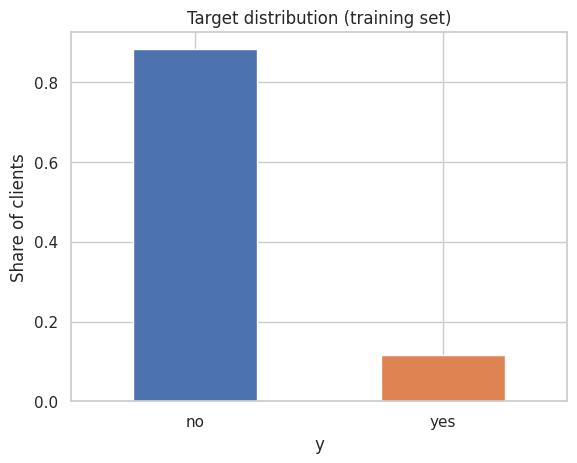

In [ ]:
ax = y_train.map({0: "no", 1: "yes"}).value_counts(normalize=True).plot(kind="bar", rot=0, color=["#4C72B0", "#DD8452"])
ax.set_title("Target distribution (training set)")
ax.set_ylabel("Share of clients")
plt.show()

**Finding.** Only 11.7% of clients subscribe, roughly one in nine. The target is clearly imbalanced, so accuracy would be misleading. We use ROC-AUC, PR-AUC and F1, and apply class weighting in the model.

### 7.2 Skewed numeric features and outliers

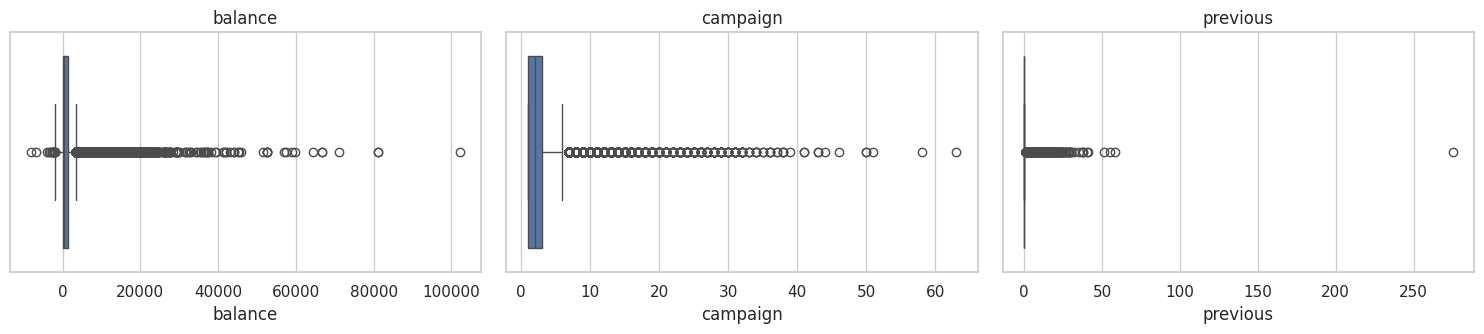

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, c in zip(axes, ["balance", "campaign", "previous"]):
    sns.boxplot(x=train[c], ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

**Finding.** `balance`, `campaign` and `previous` are strongly right-skewed with extreme values. `balance` ranges from about -8,000 to over 100,000 while its 99th percentile is only about 13,000. `campaign` reaches 63 contacts (99th percentile about 16). `previous` has a median of 0 but a maximum of 275. These extremes would dominate scaled features, so these three columns are clipped at the 1st and 99th percentiles, with the limits learned from training data only.

### 7.3 Subscription rate by job

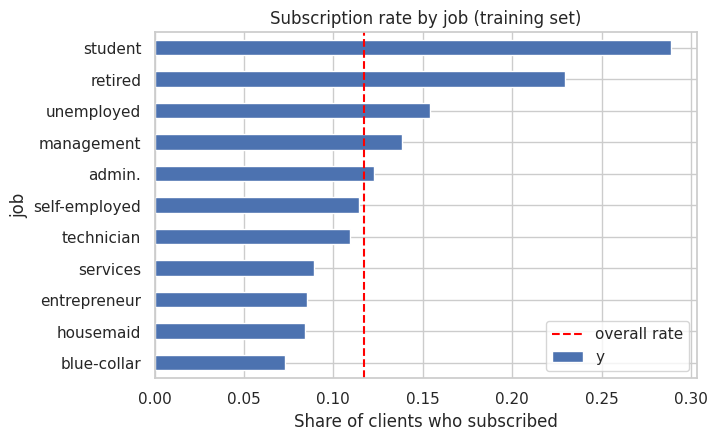

In [ ]:
rate = train.groupby("job")["y"].mean().sort_values()
ax = rate.plot(kind="barh", figsize=(7, 4.5), color="#4C72B0")
ax.axvline(y_train.mean(), color="red", linestyle="--", label="overall rate")
ax.set_title("Subscription rate by job (training set)")
ax.set_xlabel("Share of clients who subscribed")
ax.legend()
plt.show()

**Finding.** Subscription rates differ strongly by occupation. Students (about 29%) and retired clients (about 23%) subscribe far more often than average, while blue-collar clients (about 7%) subscribe least. `job` is therefore an informative feature and is one-hot encoded.

### 7.4 Missing values

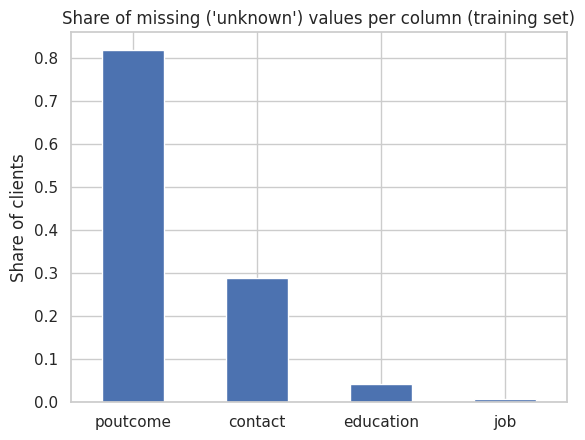

In [ ]:
missing_share = X_train.isna().mean()
missing_share = missing_share[missing_share > 0].sort_values(ascending=False)
ax = missing_share.plot(kind="bar", rot=0, color="#4C72B0")
ax.set_title("Share of missing ('unknown') values per column (training set)")
ax.set_ylabel("Share of clients")
plt.show()

**Finding.** `poutcome` is unknown for about 82% of clients and `contact` for about 29%, while `education` (about 4%) and `job` (about 0.6%) have few. For `poutcome` and `contact`, the missing entries carry meaning (mostly "not previously contacted"), so they are kept as their own `"unknown"` category instead of being replaced with the most common value, which would invent information. `job` and `education` are imputed with the most frequent value.

### 7.5 Correlation between numeric features

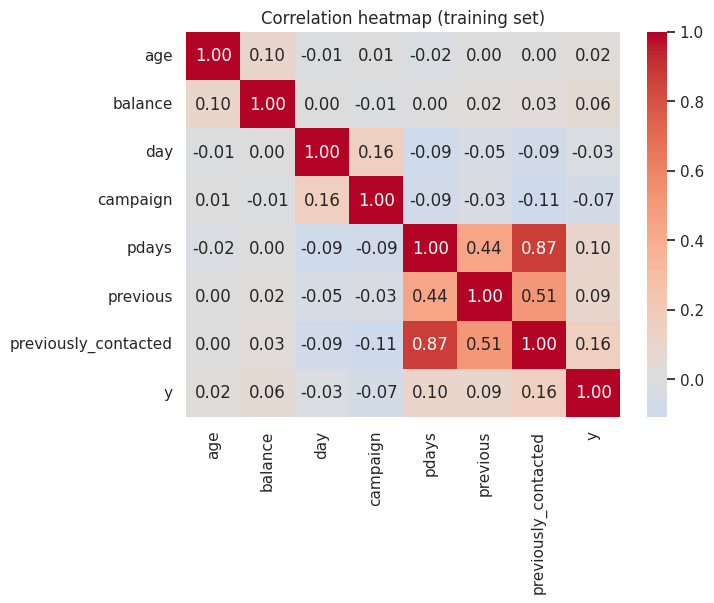

In [ ]:
num_for_corr = X_train.select_dtypes("number").assign(y=y_train)
plt.figure(figsize=(7, 5))
sns.heatmap(num_for_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap (training set)")
plt.show()

**Finding.** `pdays` and `previously_contacted` are strongly correlated (about 0.87), which is expected because the second was constructed from the first. Other numeric pairs are only weakly correlated. Both are kept for now; later parts will examine whether the redundancy matters for each model family.

## 8. Preprocessing Decisions

| Issue | Decision | Rationale | Why it does not leak |
|---|---|---|---|
| Missing numeric values | Median imputation | Median is robust to the skew seen in EDA | Median is learned on training data only (inside the pipeline) |
| Missing `contact`, `poutcome` | Constant imputation with `"unknown"` | Missingness is informative (no previous campaign) | A fixed constant, so nothing is learned |
| Missing `job`, `education` | Most-frequent imputation | Very few missing; keeps all rows | Learned on training data only |
| Outliers in `balance`, `campaign`, `previous` | Clip at 1st and 99th percentile | IQR rule fails on zero-inflated columns (Q1 = Q3) | Limits learned on training data only |
| Feature scales | `StandardScaler` | Needed by linear models and neural networks | Mean and std learned on training data only |
| Categorical features | One-hot encoding, `handle_unknown="ignore"` | No artificial ordering; unseen categories do not crash | Categories learned from training data |
| Sentinel `pdays = -1` | `previously_contacted` flag and `pdays = 0` | Prevents -1 being read as a number of days | Row-level, learns nothing |
| Class imbalance (11.7% positive) | `class_weight="balanced"` | Penalises errors on the minority class more | Model setting only |
| Many encoded columns | `SelectKBest` (ANOVA F-test, k = 20) | Keeps the most informative features | Refitted inside every cross-validation fold |

## 9. Leakage-Free Pipeline
A scikit-learn `Pipeline` bundles all preprocessing and the model into a single estimator. During cross-validation it is refitted from scratch on each training fold, so imputers, clipper, scaler, encoder and feature selector only ever learn from training data and never from the validation fold.

In [ ]:
class PercentileClipper(BaseEstimator, TransformerMixin):
    """Clip each column to its [low, high] percentiles, estimated in fit() on training data only."""
    def __init__(self, low=1, high=99):
        self.low = low
        self.high = high

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lower_, self.upper_ = np.nanpercentile(X, [self.low, self.high], axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

In [ ]:
clip_cols     = ["balance", "campaign", "previous"]                 # skewed / zero-inflated numeric
plain_cols    = ["age", "day", "pdays", "previously_contacted"]     # no clipping needed
cat_const     = ["contact", "poutcome"]                             # "unknown" is meaningful
cat_frequent  = [c for c in X_train.select_dtypes(exclude="number").columns if c not in cat_const]

print("Clipped numeric   :", clip_cols)
print("Plain numeric     :", plain_cols)
print("Categorical (const):", cat_const)
print("Categorical (freq) :", cat_frequent)

clip_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("clip",   PercentileClipper(low=1, high=99)),
    ("scale",  StandardScaler()),
])
plain_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale",  StandardScaler()),
])
cat_const_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="unknown")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
cat_freq_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocess = ColumnTransformer([
    ("clip",      clip_pipe,      clip_cols),
    ("plain",     plain_pipe,     plain_cols),
    ("cat_const", cat_const_pipe, cat_const),
    ("cat_freq",  cat_freq_pipe,  cat_frequent),
])

full_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("select", SelectKBest(score_func=f_classif, k=20)),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
full_pipeline

Clipped numeric   : ['balance', 'campaign', 'previous']
Plain numeric     : ['age', 'day', 'pdays', 'previously_contacted']
Categorical (const): ['contact', 'poutcome']
Categorical (freq) : ['job', 'marital', 'education', 'default', 'housing', 'loan', 'month']


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocess', ...), ('select', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('clip', ...), ('plain', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different tra

## 10. Pipeline Validation
The complete pipeline is evaluated with stratified 5-fold cross-validation on the **training set only**. Logistic regression serves as a simple placeholder estimator to verify that the pipeline works end to end; proper model comparison begins in Part 2.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

results = cross_validate(
    full_pipeline, X_train, y_train, cv=cv,
    scoring=["roc_auc", "average_precision", "f1"],
)

summary = pd.DataFrame({
    "metric": ["ROC-AUC", "PR-AUC", "F1 (yes class)"],
    "mean": [results["test_roc_auc"].mean(), results["test_average_precision"].mean(), results["test_f1"].mean()],
    "std":  [results["test_roc_auc"].std(),  results["test_average_precision"].std(),  results["test_f1"].std()],
}).round(3)
summary

,metric,mean,std
0,ROC-AUC,0.749,0.001
1,PR-AUC,0.382,0.007
2,F1 (yes class),0.356,0.005


**Interpretation.** The pipeline reaches a ROC-AUC of about 0.75: a randomly chosen subscriber is ranked above a randomly chosen non-subscriber about three times in four. PR-AUC is about 0.38, roughly three times the 0.117 a model with no skill would achieve (the share of subscribers). The standard deviations across folds are very small, so the pipeline behaves consistently. The modest absolute level is expected: `duration`, the most predictive feature, was deliberately removed to avoid target leakage, so the model only uses information available before the call.

In [ ]:
full_pipeline.fit(X_train, y_train)
pre = full_pipeline.named_steps["preprocess"]
selected = full_pipeline.named_steps["select"].get_support()

print("Input features              :", X_train.shape[1])
print("Columns after encoding      :", pre.transform(X_train).shape[1])
print("Columns kept by SelectKBest :", int(selected.sum()))
print()
print("Selected features:")
for name in pre.get_feature_names_out()[selected]:
    print(" -", name)

Input features              : 16
Columns after encoding      : 49
Columns kept by SelectKBest : 20

Selected features:
 - clip__balance
 - clip__campaign
 - clip__previous
 - plain__pdays
 - plain__previously_contacted
 - cat_const__contact_cellular
 - cat_const__contact_unknown
 - cat_const__poutcome_success
 - cat_const__poutcome_unknown
 - cat_freq__job_blue-collar
 - cat_freq__job_retired
 - cat_freq__job_student
 - cat_freq__housing_no
 - cat_freq__housing_yes
 - cat_freq__loan_no
 - cat_freq__month_dec
 - cat_freq__month_mar
 - cat_freq__month_may
 - cat_freq__month_oct
 - cat_freq__month_sep


## 11. Leakage Check: Why the Pipeline Matters
To illustrate the principle, the numeric features are scaled in two ways and scored with the same cross-validation folds:

- **Incorrect:** the scaler is fitted on the whole training set *before* cross-validation, so it has already seen every validation fold.
- **Correct:** the scaler is part of the pipeline and is refitted on each training fold only.

In [ ]:
num_all = clip_cols + plain_cols
X_num = X_train[num_all].fillna(X_train[num_all].median())

# Incorrect: scaler fitted on all data before cross-validation
X_scaled_leaky = StandardScaler().fit_transform(X_num)
leaky = cross_val_score(LogisticRegression(max_iter=1000, class_weight="balanced"),
                        X_scaled_leaky, y_train, cv=cv, scoring="roc_auc")

# Correct: scaler inside the pipeline
safe_pipe = Pipeline([("scale", StandardScaler()),
                      ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))])
safe = cross_val_score(safe_pipe, X_num, y_train, cv=cv, scoring="roc_auc")

print(f"Scaler fitted before CV (leaky): ROC-AUC = {leaky.mean():.4f}")
print(f"Scaler inside pipeline (safe):   ROC-AUC = {safe.mean():.4f}")

Scaler fitted before CV (leaky): ROC-AUC = 0.6478
Scaler inside pipeline (safe):   ROC-AUC = 0.6478


**Note.** For simple standard scaling the two scores are almost identical, because the mean and standard deviation of tens of thousands of rows barely change from fold to fold. The leakage risk grows with steps that use the *target* (such as feature selection or oversampling) and with small datasets. Putting every fitted step inside the pipeline removes the risk by construction, regardless of its size here.

## 12. Part 1 Summary

- **Problem:** predict whether a bank client subscribes to a term deposit (binary classification), evaluated with ROC-AUC, PR-AUC and F1.
- **Leakage controls:** `duration` removed as target leakage; data split before any learned preprocessing; all fitted steps inside a single `Pipeline`; test set untouched.
- **Cleaning and preparation:** "unknown" converted to missing; informative missingness (`contact`, `poutcome`) kept as its own category; remaining missing values imputed; skewed columns clipped at the 1st/99th percentile; `pdays` sentinel handled with a `previously_contacted` flag; numeric features standardised; categoricals one-hot encoded; 20 features selected.
- **Imbalance:** handled with class weighting (11.7% positive class).
- **Baseline pipeline performance (CV, training set):** ROC-AUC about 0.75, PR-AUC about 0.38, F1 about 0.36.
- **Outputs for later parts:** `full_pipeline`, `preprocess`, `X_train`, `X_test`, `y_train`, `y_test`.
- **Limitation:** the data is ordered roughly by time, but a stratified random split was used. A deployed model would predict future campaigns from past ones, so a time-based split would be a more realistic evaluation.

---


---
# Part 2: Supervised Learning Baseline (Naive Bayes vs Decision Tree)

**Objective.** Train and compare a probabilistic model (Naive Bayes) and a tree-based model (decision tree) on the bank-marketing data prepared in Part 1, show one split computed by hand, evaluate with a proper cross-validation scheme, and explain which model works better here and why.

In [ ]:
import warnings
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import OrdinalEncoder, KBinsDiscretizer
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.metrics import (roc_curve, precision_recall_curve, roc_auc_score,
                             average_precision_score, ConfusionMatrixDisplay, make_scorer, precision_score)

## 13. Theory: the Two Model Families

### 13.1 Naive Bayes
Naive Bayes applies Bayes' theorem and makes one strong simplifying assumption: given the class, the features are **conditionally independent**.

$$P(y \mid x_1,\dots,x_d) \;\propto\; P(y)\,\prod_{j=1}^{d} P(x_j \mid y)$$

Training is simply estimating $P(y)$ and each $P(x_j \mid y)$ from the training data, which makes it extremely fast and low-variance, even with limited data. The variants differ in how $P(x_j \mid y)$ is modelled:

| Variant | Models $P(x_j \mid y)$ as | Suitable for |
|---|---|---|
| **Gaussian NB** | A normal distribution with a class-specific mean and variance | Continuous, roughly bell-shaped features |
| **Categorical NB** | Smoothed frequency counts per category: $\hat P(x_j=c \mid y)=\dfrac{N_{c,y}+\alpha}{N_y+\alpha k_j}$ (Laplace smoothing, $\alpha = 1$) | Discrete / categorical features |

**Known weakness.** If features are strongly dependent, the independence assumption is violated and the predicted *probabilities* become over-confident. The *ranking* of clients is often still good, which is what ROC-AUC and PR-AUC measure.

### 13.2 Decision Tree
A decision tree recursively picks the feature test that makes the child nodes as **pure** as possible. Node impurity is measured by entropy or Gini impurity:

$$H = -\sum_k p_k \log_2 p_k \qquad\qquad G = 1-\sum_k p_k^2$$

$$\text{Gain}(\text{split}) \;=\; I(\text{parent}) \;-\; \sum_{c\in\{\text{left},\text{right}\}} \frac{n_c}{n}\, I(c)$$

The search is greedy (best split at each node, no look-ahead). An unrestricted tree keeps splitting until every leaf is pure, which memorises the training data (**high variance / overfitting**). Depth and leaf-size limits control this. Trees need no feature scaling and can capture interactions between features, and each prediction can be read as a rule.

### 13.3 What We Expect Before Running Anything
- **Naive Bayes:** several features are redundant (`pdays` and `previously_contacted`; the two one-hot columns of each yes/no feature), so the independence assumption is clearly violated. We expect decent ranking but not calibrated probabilities. The Gaussian assumption should fit poorly on skewed or one-hot columns, so **Categorical NB on binned data** should do at least as well as Gaussian NB.
- **Decision tree:** an unrestricted tree should overfit badly on 36,000 noisy rows. A depth-limited tree should be much better, and its best depth should be found with cross-validation rather than guessed.
- **Imbalance:** with 11.7% positives, accuracy will be uninformative (a constant "no" scores 88.3%), so the comparison must rest on ROC-AUC, PR-AUC and F1.

## 14. Hand-Worked Split Calculation
To make the splitting criterion concrete, we compute one split **by hand** on a small worked case taken from our own training data.

**The worked case.** 20 clients are drawn at random from the training set (fixed seed): 6 subscribers and 14 non-subscribers. This toy sample is deliberately enriched with subscribers (30% instead of 11.7%) so that every node has something to compute. It is used only for this illustration; it plays no role in model training.

In [ ]:
toy_pos = train[train["y"] == 1].sample(6,  random_state=7)
toy_neg = train[train["y"] == 0].sample(14, random_state=7)
toy = pd.concat([toy_pos, toy_neg]).sample(frac=1, random_state=7)

print("Toy sample:", len(toy), "clients,", int(toy["y"].sum()), "subscribers")
toy[["age", "job", "housing", "contact", "poutcome", "previously_contacted", "y"]]

Toy sample: 20 clients, 6 subscribers


,age,job,housing,contact,poutcome,previously_contacted,y
28001,46,technician,no,cellular,NaN,0,1
28363,34,technician,no,cellular,failure,1,0
43803,46,housemaid,no,cellular,success,1,1
40699,72,retired,no,cellular,NaN,0,1
8509,33,technician,yes,NaN,NaN,0,0
15222,31,management,yes,cellular,NaN,0,1
30770,40,management,no,cellular,NaN,0,0
8401,54,blue-collar,yes,NaN,NaN,0,0
26006,40,admin.,no,cellular,success,1,0
2027,33,technician,yes,NaN,NaN,0,0


**Candidate split:** `poutcome == "success"` (the client's outcome in the *previous* campaign was a success) versus everything else. Counting the rows in the toy sample:

| Node | Clients | Subscribers (yes) | Non-subscribers (no) |
|---|---|---|---|
| Parent (all 20) | 20 | 6 | 14 |
| Left: `poutcome = success` | 4 | 3 | 1 |
| Right: `poutcome ≠ success` | 16 | 3 | 13 |

### Entropy and information gain

**Parent node:** $p(\text{yes}) = 6/20 = 0.30$

$$H(\text{parent}) = -0.30\log_2 0.30 - 0.70\log_2 0.70 = 0.30(1.7370) + 0.70(0.5146) = 0.5211 + 0.3602 = \mathbf{0.8813}$$

**Left child** ($p = 3/4 = 0.75$):

$$H(\text{left}) = -0.75\log_2 0.75 - 0.25\log_2 0.25 = 0.75(0.4150) + 0.25(2.0000) = 0.3113 + 0.5000 = \mathbf{0.8113}$$

**Right child** ($p = 3/16 = 0.1875$):

$$H(\text{right}) = -0.1875\log_2 0.1875 - 0.8125\log_2 0.8125 = 0.1875(2.4150) + 0.8125(0.2996) = 0.4528 + 0.2434 = \mathbf{0.6962}$$

**Weighted average of the children:**

$$H_{\text{after}} = \tfrac{4}{20}(0.8113) + \tfrac{16}{20}(0.6962) = 0.1623 + 0.5570 = 0.7192$$

$$\boxed{\text{Information Gain} = 0.8813 - 0.7192 = 0.1621 \text{ bits}}$$

### Gini impurity and Gini gain

$$G(\text{parent}) = 1-(0.30^2+0.70^2) = 1-0.58 = \mathbf{0.4200}$$
$$G(\text{left}) = 1-(0.75^2+0.25^2) = 1-0.6250 = \mathbf{0.3750}$$
$$G(\text{right}) = 1-(0.1875^2+0.8125^2) = 1-0.6953 = \mathbf{0.3047}$$
$$G_{\text{after}} = \tfrac{4}{20}(0.3750) + \tfrac{16}{20}(0.3047) = 0.0750 + 0.2438 = 0.3188$$

$$\boxed{\text{Gini Gain} = 0.4200 - 0.3188 = 0.1013}$$

The code below recomputes both numbers to confirm the hand calculation, and compares this split with three other candidates on the same 20 clients.

In [ ]:
def entropy(p):
    probs = np.array([p, 1 - p]);  probs = probs[probs > 0]
    return float(-(probs * np.log2(probs)).sum())

def gini(p):
    return 1 - p**2 - (1 - p)**2

def split_gain(n, n_yes, n_left, yes_left, impurity):
    n_right, yes_right = n - n_left, n_yes - yes_left
    parent = impurity(n_yes / n)
    left   = impurity(yes_left / n_left)
    right  = impurity(yes_right / n_right)
    after  = n_left / n * left + n_right / n * right
    return {"parent": parent, "left": left, "right": right, "after": after, "gain": parent - after}

# Verify the hand calculation for poutcome == "success"
h = split_gain(20, 6, 4, 3, entropy)
g = split_gain(20, 6, 4, 3, gini)
print(f"Entropy: parent={h['parent']:.4f}  left={h['left']:.4f}  right={h['right']:.4f}  after={h['after']:.4f}  gain={h['gain']:.4f}")
print(f"Gini   : parent={g['parent']:.4f}  left={g['left']:.4f}  right={g['right']:.4f}  after={g['after']:.4f}  gain={g['gain']:.4f}")

Entropy: parent=0.8813  left=0.8113  right=0.6962  after=0.7192  gain=0.1621
Gini   : parent=0.4200  left=0.3750  right=0.3047  after=0.3188  gain=0.1013


In [ ]:
candidates = {
    'poutcome == "success"':     toy["poutcome"] == "success",
    'contact == "cellular"':     toy["contact"] == "cellular",
    'housing == "no"':           toy["housing"] == "no",
    "previously_contacted == 1": toy["previously_contacted"] == 1,
}
rows = []
for name, mask in candidates.items():
    n_left, yes_left = int(mask.sum()), int(toy.loc[mask, "y"].sum())
    rows.append({
        "split": name,
        "left (n, yes)": f"({n_left}, {yes_left})",
        "right (n, yes)": f"({20 - n_left}, {6 - yes_left})",
        "information gain": split_gain(20, 6, n_left, yes_left, entropy)["gain"],
        "Gini gain":        split_gain(20, 6, n_left, yes_left, gini)["gain"],
    })
pd.DataFrame(rows).round(4)

,split,"left (n, yes)","right (n, yes)",information gain,Gini gain
0,"poutcome == ""success""","(4, 3)","(16, 3)",0.1621,0.1013
1,"contact == ""cellular""","(14, 6)","(6, 0)",0.1916,0.0771
2,"housing == ""no""","(11, 5)","(9, 1)",0.1081,0.0584
3,previously_contacted == 1,"(8, 3)","(12, 3)",0.0128,0.0075


**Reading the table.** In this tiny sample, `contact == "cellular"` actually has a slightly higher gain than `poutcome == "success"`, because 6 clients with an unknown/telephone contact all happen to be non-subscribers. With only 20 rows such a result can easily be a coincidence, which is exactly why a split should be judged on far more data. The next cell repeats the same calculation on the **full training set** (36,168 clients) and checks it against what scikit-learn's tree actually chooses as its first split.

In [ ]:
n_all, yes_all = len(y_train), int(y_train.sum())
mask = (X_train["poutcome"] == "success")
n_left, yes_left = int(mask.sum()), int(y_train[mask].sum())

print(f"Full training set: {n_all} clients, {yes_all} subscribers ({yes_all / n_all:.1%})")
print(f"poutcome == success : {n_left} clients, {yes_left} subscribers ({yes_left / n_left:.1%})")
print(f"poutcome != success : {n_all - n_left} clients, {yes_all - yes_left} subscribers ({(yes_all - yes_left) / (n_all - n_left):.1%})")
print()
print("Information gain (hand formula):", round(split_gain(n_all, yes_all, n_left, yes_left, entropy)["gain"], 4))
print("Gini gain (hand formula)       :", round(split_gain(n_all, yes_all, n_left, yes_left, gini)["gain"], 4))

# What does scikit-learn pick as the very first split (a depth-1 tree)?
Z = preprocess.fit_transform(X_train, y_train)
feature_names = preprocess.get_feature_names_out()
for criterion in ["gini", "entropy"]:
    stump = DecisionTreeClassifier(max_depth=1, criterion=criterion, random_state=RANDOM_STATE).fit(Z, y_train)
    t = stump.tree_
    print(f"Root split chosen with criterion={criterion!r}: {feature_names[t.feature[0]]} <= {t.threshold[0]}")
    if criterion == "gini":
        gain = t.impurity[0] - (t.n_node_samples[1] * t.impurity[1] + t.n_node_samples[2] * t.impurity[2]) / t.n_node_samples[0]
        print(f"    Gini gain reported by the fitted tree: {gain:.4f}")

Full training set: 36168 clients, 4231 subscribers (11.7%)
poutcome == success : 1205 clients, 779 subscribers (64.6%)
poutcome != success : 34963 clients, 3452 subscribers (9.9%)

Information gain (hand formula): 0.0399
Gini gain (hand formula)       : 0.0193


Root split chosen with criterion='gini': cat_const__poutcome_success <= 0.5
    Gini gain reported by the fitted tree: 0.0193
Root split chosen with criterion='entropy': cat_const__poutcome_success <= 0.5


**Result.** On the full training data the same formulas give an information gain of about 0.040 bits and a Gini gain of about 0.019 for the split `poutcome == "success"`, and both match the tree. Both criteria choose this same feature as the **root split** of the real tree. This is plausible: only 3.3% of clients (1,205 of 36,168) had a successful previous campaign, but 64.6% of them subscribed again, compared with 9.9% of everyone else. The hand calculation on 20 rows therefore illustrates the real mechanism that drives the full model.

## 15. Evaluation Methodology

| Decision | Choice | Reason |
|---|---|---|
| Data used | Training set only (`X_train`, `y_train`); the test set stays untouched | Final unbiased evaluation is reserved for later parts |
| Scheme | Stratified 5-fold cross-validation, the same folds for every model (`random_state=42`) | Keeps the 11.7% positive rate in every fold and makes models directly comparable |
| Leakage control | Every model is a full `Pipeline`, refitted on each training fold | Imputers, clipper, scaler, encoders and bin edges never see the validation fold |
| Threshold-free metrics | **ROC-AUC** and **PR-AUC** (average precision) | Measure how well a model *ranks* clients, independent of the cut-off; PR-AUC is the more informative one under imbalance |
| Threshold-dependent metrics | Accuracy, precision, recall, **F1** (positive class) | Describe the model's actual yes/no decisions |
| Reference | Majority-class baseline (always "no") | Anything we build must beat it on ROC-AUC/PR-AUC/F1; its 88.3% accuracy shows why accuracy alone is misleading |
| Tuning honesty | Tree depth tuned with a **nested** cross-validation (inner folds choose the depth, outer folds score it) | Choosing the best depth on the same folds that report the score gives an over-optimistic number |

## 16. Model Definitions
Each model is a complete pipeline.

- **Gaussian NB** uses the Part 1 preprocessing (clipped and standardised numbers plus one-hot categoricals). It needs a dense array, so the `ColumnTransformer` is cloned with `sparse_threshold=0`.
- **Categorical NB** needs discrete inputs, so numeric columns are discretised into 8 quantile bins and categorical columns are ordinal-encoded. Quantile bins make explicit outlier clipping unnecessary. Unseen categories map to a spare index, and Laplace smoothing handles zero counts.
- **Decision trees** reuse the Part 1 preprocessing (scaling does not matter to a tree, but this keeps the comparison on identical inputs) with `class_weight="balanced"` to counter the imbalance. Naive Bayes has no class weights, so it keeps the natural class priors; one extra variant with uniform priors shows the effect.

In [ ]:
# KBinsDiscretizer merges duplicate quantile edges on zero-inflated columns and issues a warning; this is expected.
import os
os.environ["PYTHONWARNINGS"] = "ignore"       # also applies to parallel worker processes
warnings.filterwarnings("ignore", category=UserWarning, message=".*Bins whose width are too small.*")
warnings.filterwarnings("ignore", category=FutureWarning, message=".*quantile_method.*")

# --- Preprocessing variants -------------------------------------------------------------
preprocess_dense = clone(preprocess).set_params(sparse_threshold=0)       # dense output for GaussianNB

numeric_nb     = clip_cols + plain_cols
categorical_nb = cat_const + cat_frequent
preprocess_categorical = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("bin",    KBinsDiscretizer(n_bins=8, encode="ordinal", strategy="quantile"))]), numeric_nb),
    ("cat", Pipeline([("impute",  SimpleImputer(strategy="constant", fill_value="unknown")),
                      ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=14))]), categorical_nb),
])

# --- Models -------------------------------------------------------------------------------
models = {
    "Majority-class baseline": Pipeline([("model", DummyClassifier(strategy="prior"))]),
    "Gaussian NB": Pipeline([("preprocess", preprocess_dense), ("model", GaussianNB())]),
    "Categorical NB": Pipeline([("preprocess", preprocess_categorical), ("model", CategoricalNB(min_categories=15))]),
    "Categorical NB (uniform priors)": Pipeline([("preprocess", preprocess_categorical),
                                                  ("model", CategoricalNB(min_categories=15, fit_prior=False))]),
    "Decision tree (unlimited depth)": Pipeline([("preprocess", preprocess),
                                                  ("model", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE))]),
    "Decision tree (max_depth=8)": Pipeline([("preprocess", preprocess),
                                              ("model", DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=RANDOM_STATE))]),
}
list(models)

['Majority-class baseline',
 'Gaussian NB',
 'Categorical NB',
 'Categorical NB (uniform priors)',
 'Decision tree (unlimited depth)',
 'Decision tree (max_depth=8)']

## 17. Cross-Validation Results
The depth 8 in the last model comes from the depth analysis in Section 18; the nested cross-validation row below confirms that choosing the depth did not inflate the result.

In [ ]:
scoring = {"accuracy": "accuracy",
           "precision": make_scorer(precision_score, zero_division=0),   # the majority baseline predicts no positives
           "recall": "recall", "f1": "f1", "roc_auc": "roc_auc", "pr_auc": "average_precision"}

fold_scores = {}
for name, model in models.items():
    r = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    fold_scores[name] = {k: r[f"test_{k}"] for k in scoring}

# Nested CV for the tree: inner 3-fold search over depth, outer 5-fold (same folds as above) for scoring
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
tuned_tree = GridSearchCV(
    Pipeline([("preprocess", preprocess),
              ("model", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE))]),
    param_grid={"model__max_depth": list(range(3, 13))},
    scoring="roc_auc", cv=inner_cv, n_jobs=-1,
)
nested = cross_validate(tuned_tree, X_train, y_train, cv=cv, scoring=scoring, return_estimator=True)
fold_scores["Decision tree (depth tuned, nested CV)"] = {k: nested[f"test_{k}"] for k in scoring}
print("Depths chosen by the inner search in each outer fold:",
      [e.best_params_["model__max_depth"] for e in nested["estimator"]])

results = pd.DataFrame({name: {k: v.mean() for k, v in d.items()} for name, d in fold_scores.items()}).T
results["roc_auc_std"] = [d["roc_auc"].std() for d in fold_scores.values()]
results.columns = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC", "ROC-AUC std"]
results.round(3)

Depths chosen by the inner search in each outer fold: [7, 7, 8, 7, 7]


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,ROC-AUC std
Majority-class baseline,0.883,0.000,0.000,0.000,0.500,0.117,0.000
Gaussian NB,0.828,0.330,0.458,0.383,0.740,0.334,0.003
Categorical NB,0.871,0.435,0.355,0.391,0.752,0.375,0.002
Categorical NB (uniform priors),0.725,0.243,0.637,0.352,0.752,0.375,0.002
Decision tree (unlimited depth),0.837,0.306,0.310,0.308,0.608,0.176,0.008
Decision tree (max_depth=8),0.810,0.328,0.572,0.415,0.754,0.372,0.005
"Decision tree (depth tuned, nested CV)",0.815,0.337,0.561,0.418,0.752,0.362,0.003


**Reading the table.**

- **Accuracy is misleading.** The majority-class baseline has the highest accuracy (88.3%) while finding no subscribers (recall 0, F1 0). Every real model has *lower* accuracy because it deliberately says "yes" more often to catch subscribers. This is why the comparison rests on ROC-AUC, PR-AUC and F1.
- **Both model families clearly beat the baseline:** ROC-AUC is about 0.75 versus 0.50, and PR-AUC is about 0.37 versus 0.117.
- **The unrestricted tree is the worst real model.** It memorises the training data (see Section 18) and generalises poorly.
- **Categorical NB beats Gaussian NB** on PR-AUC and accuracy, as predicted: discretising respects the skewed and categorical nature of the features.
- **Prior vs threshold.** Categorical NB with uniform priors has *identical* ROC-AUC and PR-AUC to the version with natural priors (changing the prior only shifts the cut-off, not the ranking), but recall rises and precision falls: a pure precision/recall trade-off.

## 18. Why the Unlimited Tree Fails: Depth vs Generalisation
The plot compares the tree's ROC-AUC on the data it was trained on against its ROC-AUC on held-out folds, for increasing depth.

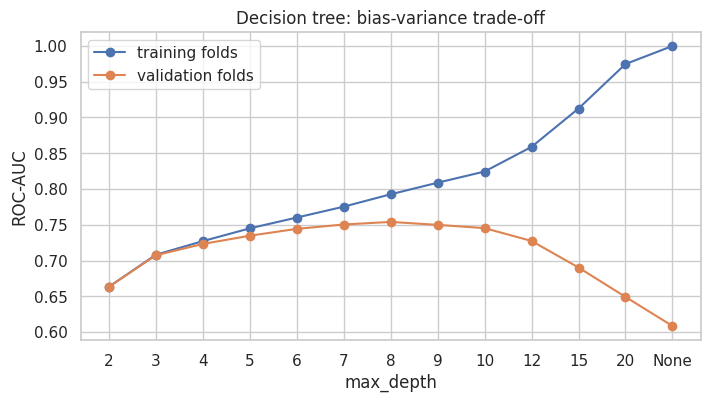

,max_depth,train ROC-AUC,CV ROC-AUC
0,2,0.663,0.663
1,3,0.708,0.707
2,4,0.727,0.723
3,5,0.745,0.735
4,6,0.760,0.744
5,7,0.775,0.750
6,8,0.793,0.754
7,9,0.809,0.750
8,10,0.824,0.745
9,12,0.859,0.727


In [ ]:
depths = [2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15, 20, None]
curve = []
for d in depths:
    m = Pipeline([("preprocess", preprocess),
                  ("model", DecisionTreeClassifier(max_depth=d, class_weight="balanced", random_state=RANDOM_STATE))])
    r = cross_validate(m, X_train, y_train, cv=cv, scoring="roc_auc", return_train_score=True)
    curve.append({"max_depth": "None" if d is None else d,
                  "train ROC-AUC": r["train_score"].mean(), "CV ROC-AUC": r["test_score"].mean()})
curve = pd.DataFrame(curve)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curve["max_depth"].astype(str), curve["train ROC-AUC"], marker="o", label="training folds")
ax.plot(curve["max_depth"].astype(str), curve["CV ROC-AUC"],    marker="o", label="validation folds")
ax.set_xlabel("max_depth"); ax.set_ylabel("ROC-AUC"); ax.set_title("Decision tree: bias-variance trade-off")
ax.legend(); plt.show()
curve.round(3)

**Finding.** Training ROC-AUC keeps climbing towards 1.0 as the tree gets deeper, but validation ROC-AUC peaks at a depth of about 8 and then falls sharply: beyond that the tree is fitting noise rather than signal (classic overfitting, i.e. high variance). Shallow trees (depth 2 to 3) underfit (high bias). The nested cross-validation chooses depths around 7 to 8 in every outer fold and scores almost the same as the fixed depth of 8, so the selected depth is reliable and its score is not an artefact of tuning on the evaluation folds.

## 19. Ranking Quality and Error Types
The curves below use out-of-fold predictions: every client is scored by a model that never saw that client during training.

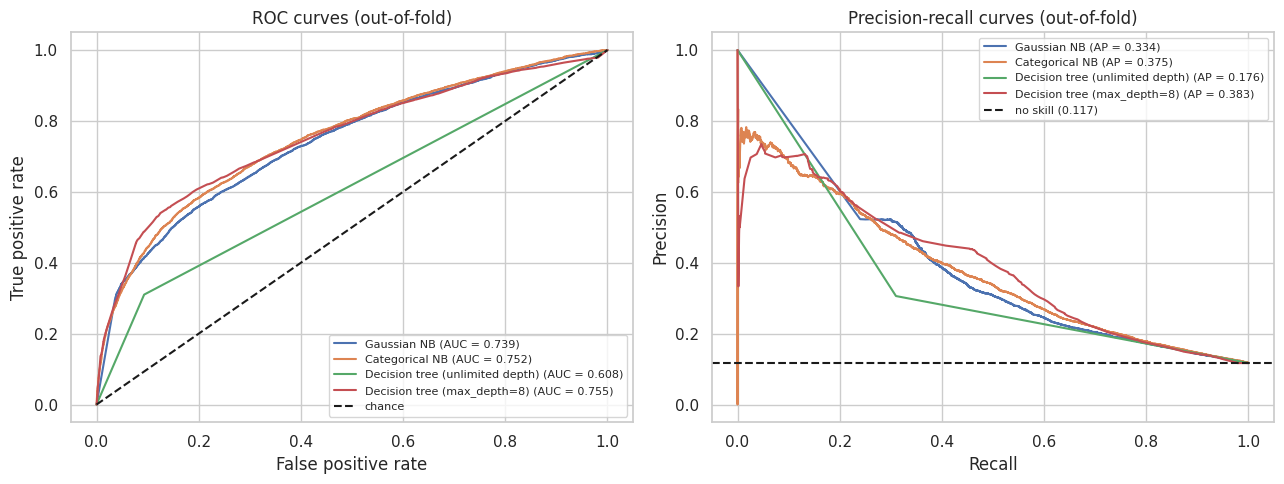

In [ ]:
plot_models = ["Gaussian NB", "Categorical NB", "Decision tree (unlimited depth)", "Decision tree (max_depth=8)"]
oof_proba = {n: cross_val_predict(models[n], X_train, y_train, cv=cv, method="predict_proba")[:, 1] for n in plot_models}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for n, p in oof_proba.items():
    fpr, tpr, _ = roc_curve(y_train, p)
    axes[0].plot(fpr, tpr, label=f"{n} (AUC = {roc_auc_score(y_train, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_train, p)
    axes[1].plot(rec, prec, label=f"{n} (AP = {average_precision_score(y_train, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="chance"); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curves (out-of-fold)"); axes[0].legend(fontsize=8)
axes[1].axhline(y_train.mean(), color="k", linestyle="--", label=f"no skill ({y_train.mean():.3f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-recall curves (out-of-fold)"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

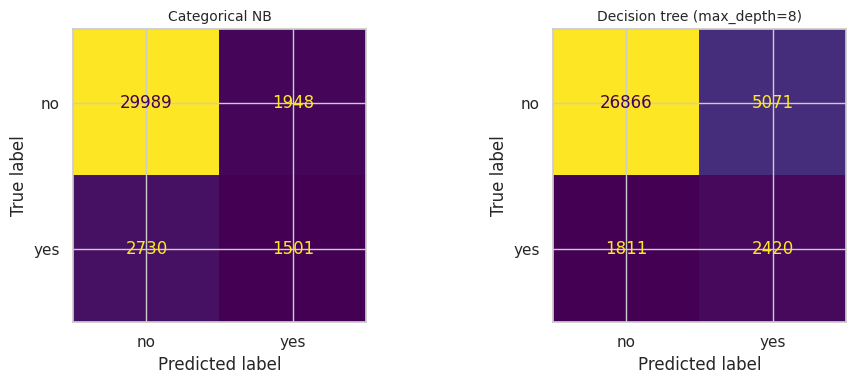

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, n in zip(axes, ["Categorical NB", "Decision tree (max_depth=8)"]):
    pred = cross_val_predict(models[n], X_train, y_train, cv=cv)
    ConfusionMatrixDisplay.from_predictions(y_train, pred, display_labels=["no", "yes"], ax=ax, colorbar=False, values_format="d")
    ax.set_title(n, fontsize=10)
plt.tight_layout(); plt.show()

**Finding.** The ROC curves of Categorical NB and the depth-8 tree are very close (the tree is slightly higher at low false-positive rates), and in the precision-recall plot both sit well above the unlimited tree and moderately above Gaussian NB. (Pooled out-of-fold values differ slightly from the fold averages in the table.) The confusion matrices show the difference in *behaviour* at the default decision rule: Naive Bayes (natural priors) is conservative, missing more subscribers but making fewer false alarms, while the class-weighted tree catches more subscribers at the cost of more false positives.

## 20. Interpreting the Tree
A decision tree can be read as a set of rules. The plot shows its first three levels, and the bar chart shows the most important features. The node `value` entries are class-weighted counts (balanced weights), which is why the root shows equal weight for both classes.

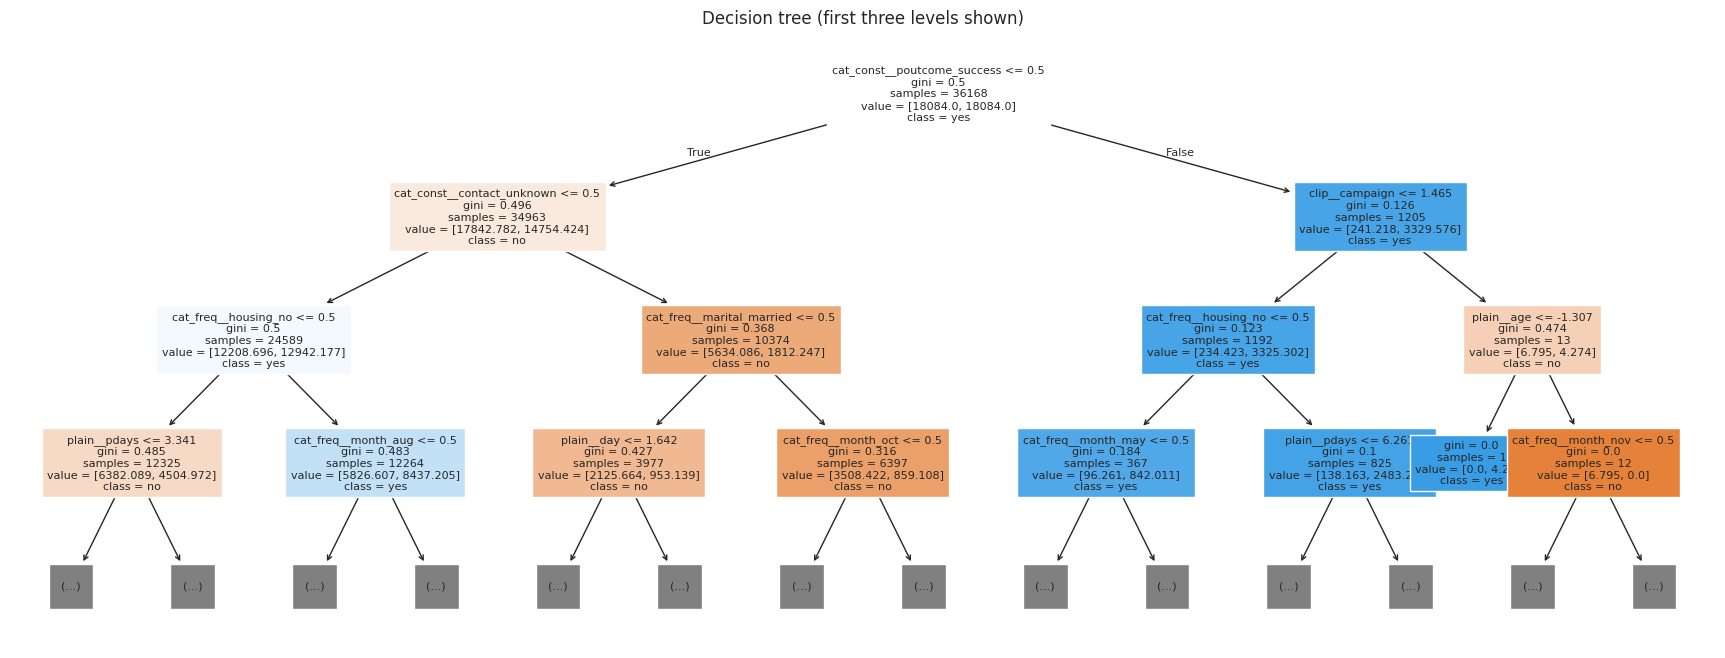

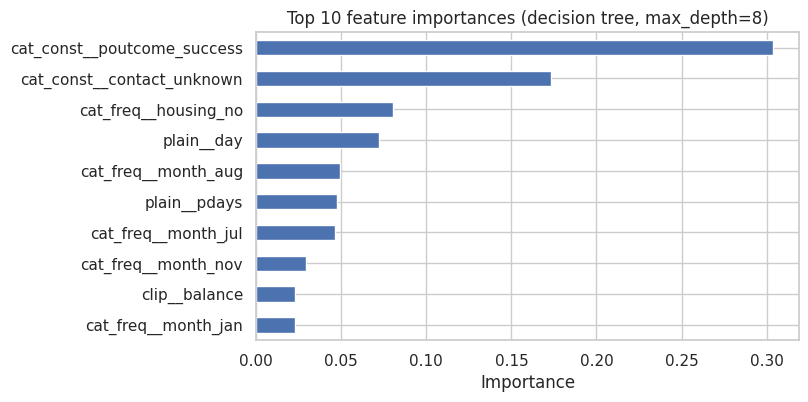

In [ ]:
final_tree = Pipeline([("preprocess", preprocess),
                       ("model", DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=RANDOM_STATE))]).fit(X_train, y_train)
tree_model = final_tree.named_steps["model"]
names = final_tree.named_steps["preprocess"].get_feature_names_out()

fig, ax = plt.subplots(figsize=(22, 8))
plot_tree(tree_model, max_depth=3, feature_names=names, class_names=["no", "yes"], filled=True, fontsize=8, ax=ax)
plt.title("Decision tree (first three levels shown)"); plt.show()

importance = pd.Series(tree_model.feature_importances_, index=names).sort_values(ascending=False).head(10)
ax = importance[::-1].plot(kind="barh", figsize=(7, 4), color="#4C72B0")
ax.set_title("Top 10 feature importances (decision tree, max_depth=8)"); ax.set_xlabel("Importance")
plt.show()

**Finding.** The tree splits first on the outcome of the previous campaign, which matches the hand-worked split and the EDA from Part 1; its two second-level splits are on whether the contact type is unknown and on the number of contacts in this campaign. `poutcome = success` carries about 30% of the total importance and `contact = unknown` about 17%, followed by `housing`, the day of the month, and the months August, July and November. In other words, *whether and how a client was reached before and when the call took place* matter most, which a marketing team could act on directly. The importance of `day` and `month` also hints at seasonality in the campaign schedule, which a time-aware evaluation would need to take into account.

## 21. Comparison: Which Model Performs Better, and Why?

**Overall verdict: on ranking quality the two families are effectively tied, so the choice depends on what we need.** Categorical Naive Bayes (ROC-AUC 0.752, PR-AUC 0.375) and the depth-tuned decision tree (ROC-AUC 0.752 to 0.754, PR-AUC 0.362 to 0.372) differ by less than the fold-to-fold noise (standard deviation of about 0.002 to 0.005 in ROC-AUC across folds), and the per-fold winner alternates. The unrestricted tree and Gaussian NB are clearly weaker.

**Why Naive Bayes does well despite a false assumption.** Many features are redundant, so the independence assumption is violated and its probabilities are not well calibrated. But Naive Bayes only has to *order* clients correctly, and summing evidence from many weak, mostly independent signals does this well. It has very few parameters, so it is stable (low variance) and cannot overfit the way a deep tree can. Gaussian NB does worse because bell-shaped densities fit one-hot flags and heavily skewed numbers poorly; binning for Categorical NB fixes this.

**Why the tree needs constraint.** An unlimited tree reaches a training ROC-AUC of 1.0 but only about 0.6 on validation data: it memorises noise. Limiting depth to about 8 removes this and lets the tree capture interactions that Naive Bayes cannot (for example, that a previous success matters differently depending on contact type and month).

**Trade-offs.** The class-weighted tree has higher recall (about 0.57 vs 0.36) and F1 (about 0.42 vs 0.39), but this is largely a threshold effect: class weights shift the tree's decision boundary, and giving Naive Bayes uniform priors produces a similar recall-for-precision trade. Naive Bayes is faster and more stable, while the tree is easier to explain as rules.

**Decision for Part 3.** We carry both forward: the tuned tree is the natural base learner for ensembles (random forests, boosting reduce its variance), and Categorical NB remains a fast probabilistic benchmark. Part 3 will tune thresholds and hyperparameters properly, and will first need to ask whether the ensembles beat this ROC-AUC ceiling of about 0.75.

## 22. Part 2 Summary

- **Models trained:** Gaussian NB, Categorical NB (natural and uniform priors), an unlimited decision tree, a depth-8 decision tree, and a depth-tuned tree via nested cross-validation, all against a majority-class baseline.
- **Hand-worked split:** information gain 0.1621 bits and Gini gain 0.1013 for `poutcome == "success"` on a 20-client sample; the same formulas on the full training set match scikit-learn's root split.
- **Evaluation:** stratified 5-fold cross-validation with identical folds, leakage-free pipelines, ROC-AUC, PR-AUC and F1 as the main metrics (accuracy reported but explained as misleading), nested CV for the tuned tree. The test set is still untouched.
- **Findings:** both families reach ROC-AUC of about 0.75 and PR-AUC of about 0.37; an unlimited tree overfits (training AUC 1.0, validation about 0.6); Categorical NB outperforms Gaussian NB; the previous-campaign outcome is the dominant signal.
- **Limitations:** the models use default or lightly tuned settings; the imbalance is handled only through class weights and priors; decision thresholds are not tuned; the random split ignores the time ordering of the data. Part 3 addresses tuning, regularisation and ensembles.


---
## References and Acknowledgements

- Moro, S., Cortez, P., & Rita, P. (2014). *A data-driven approach to predict the success of bank telemarketing.* Decision Support Systems, 62, 22-31.
- UCI Machine Learning Repository: Bank Marketing dataset. https://archive.ics.uci.edu/dataset/222/bank+marketing
- Pedregosa et al. (2011). *Scikit-learn: Machine learning in Python.* Journal of Machine Learning Research, 12, 2825-2830.
- Quinlan, J. R. (1986). *Induction of decision trees.* Machine Learning, 1(1), 81-106.
- Breiman, L., Friedman, J., Olshen, R., & Stone, C. (1984). *Classification and Regression Trees.* Wadsworth.
- Scikit-learn user guide: Naive Bayes and Decision Trees. https://scikit-learn.org/stable/modules/naive_bayes.html
- The notebook structure and code were developed with assistance from Claude (Anthropic). The group ran, reviewed and validated all code and results.